# 03-2 baseline - raw data

이 노트북에서 하는 일: 원본 뉴스 데이터를 최소한으로 처리하고, 중복 누수를 제거한 뒤 KoBART를 파인튜닝한다.

수업 노트북 `7_1.ipynb`의 BART 학습 흐름을 따릅니다.

- `TensorDataset`, `DataLoader`, `RandomSampler`, `SequentialSampler`
- `BartForConditionalGeneration`과 `AdamW`
- 직접 작성한 `train()`과 `evaluation()`
- validation loss가 가장 낮은 `state_dict` 저장
- 수업 노트북 `7_3.ipynb`처럼 `model.generate()`로 실제 요약 생성

데이터 처리 원칙:

- 원본 test 2,740건은 고정한다.
- test와 동일한 본문 또는 summary로 연결된 train/validation 행은 학습에서 제외한다.
- train과 validation 사이의 중복 그룹은 validation 쪽으로 모은다.
- 공백 정규화는 중복 탐지에만 사용하고, 모델에는 원문을 그대로 넣는다.


## 1. 환경 및 설정

In [12]:
import os
import sys
from pathlib import Path

PROJECT = Path(r"C:\Users\KDS-30\Desktop\Projects\06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "00_baseline_raw_data"
MODEL_PATH = RESULTS / "best_model_state.pt"
MANIFEST_PATH = RESULTS / "split_manifest.csv"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 3e-5
RUN_TRAINING = True  # 파인튜닝을 시작할 때만 True로 변경

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\00_baseline_raw_data


In [13]:
import hashlib
import json
import random
import re
import time

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. 원본 데이터 로드

In [14]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha
raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)

split_order = ["train", "validation", "test"]
frames = []
for source_split in split_order:
    frame = raw_dataset[source_split].to_pandas()
    frame.insert(0, "source_index", np.arange(len(frame), dtype=np.int64))
    frame.insert(0, "source_split", source_split)
    frame.insert(0, "row_id", source_split + ":" + frame["source_index"].astype(str))
    frames.append(frame)

all_df = pd.concat(frames, ignore_index=True)
assert all_df["row_id"].is_unique
assert all_df[["document", "summary"]].notna().all().all()
assert all_df["document"].str.strip().ne("").all()
assert all_df["summary"].str.strip().ne("").all()

print("dataset revision:", dataset_revision)
print("model revision:", model_revision)
display(all_df.groupby("source_split", sort=False).size().rename("rows").to_frame())

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
model revision: f5899cc556216353e23ee36b66fad52b902066c5


,rows
source_split,
train,22194
validation,2466
test,2740


## 3. 중복 그룹과 고정 test split

이 부분은 수업의 모델 학습 내용이 아니라, 프로젝트 데이터 누수를 막기 위한 추가 전처리입니다. 동일 본문 또는 동일 정답 요약으로 연결된 행을 같은 그룹으로 봅니다.

원본 test를 고정하면서 누수를 없애려면 test 그룹과 연결된 train/validation 행을 동시에 사용할 수 없습니다. 해당 행은 `excluded_test_overlap`으로 기록하고 학습에서만 제외합니다.


In [15]:
whitespace_pattern = re.compile(r"\s+")

def normalize_for_duplicate_check(text):
    return whitespace_pattern.sub(" ", str(text)).strip()

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

class UnionFind:
    def __init__(self, size):
        self.parent = list(range(size))

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, left, right):
        left_root = self.find(left)
        right_root = self.find(right)
        if left_root != right_root:
            self.parent[right_root] = left_root

document_hashes = all_df["document"].map(normalize_for_duplicate_check).map(text_hash)
summary_hashes = all_df["summary"].map(normalize_for_duplicate_check).map(text_hash)

union_find = UnionFind(len(all_df))
for hashes in [document_hashes, summary_hashes]:
    first_index = {}
    for index, value_hash in enumerate(hashes):
        if value_hash in first_index:
            union_find.union(index, first_index[value_hash])
        else:
            first_index[value_hash] = index

roots = [union_find.find(index) for index in range(len(all_df))]
root_to_group = {root: group_id for group_id, root in enumerate(sorted(set(roots)))}
group_ids = np.array([root_to_group[root] for root in roots])

group_sources = (
    pd.DataFrame({"group_id": group_ids, "source_split": all_df["source_split"]})
    .groupby("group_id")["source_split"]
    .agg(set)
)
test_groups = set(group_sources[group_sources.map(lambda values: "test" in values)].index)
validation_groups = set(
    group_sources[
        group_sources.map(lambda values: "validation" in values and "test" not in values)
    ].index
)

assigned_split = []
for source_split, group_id in zip(all_df["source_split"], group_ids):
    if source_split == "test":
        assigned_split.append("test")
    elif group_id in test_groups:
        assigned_split.append("excluded_test_overlap")
    elif group_id in validation_groups:
        assigned_split.append("validation")
    else:
        assigned_split.append("train")

manifest = pd.DataFrame({
    "row_id": all_df["row_id"],
    "source_split": all_df["source_split"],
    "source_index": all_df["source_index"],
    "assigned_split": assigned_split,
    "group_id": group_ids,
    "document_sha256": document_hashes,
    "summary_sha256": summary_hashes,
})
manifest.to_csv(MANIFEST_PATH, index=False, encoding="utf-8-sig")

display(pd.crosstab(manifest["source_split"], manifest["assigned_split"]))
print("전체 그룹:", f"{len(set(group_ids)):,}")
print("manifest:", MANIFEST_PATH)

assigned_split,excluded_test_overlap,test,train,validation
source_split,,,,
test,0,2740,0,0
train,894,0,20839,461
validation,116,0,0,2350


전체 그룹: 24,804
manifest: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\00_baseline_raw_data\split_manifest.csv


## 4. 데이터 누수 검증

In [16]:
used_manifest = manifest[manifest["assigned_split"].isin(split_order)].copy()

assert len(manifest.loc[manifest["source_split"].eq("test")]) == 2740
assert len(manifest.loc[manifest["assigned_split"].eq("test")]) == 2740
assert manifest.loc[manifest["source_split"].eq("test"), "assigned_split"].eq("test").all()
assert used_manifest.groupby("group_id")["assigned_split"].nunique().max() == 1

def overlap_count(column, left, right):
    left_values = set(used_manifest.loc[used_manifest["assigned_split"].eq(left), column])
    right_values = set(used_manifest.loc[used_manifest["assigned_split"].eq(right), column])
    return len(left_values & right_values)

leakage_rows = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        leakage_rows.append({
            "left": left,
            "right": right,
            "document_overlap": overlap_count("document_sha256", left, right),
            "summary_overlap": overlap_count("summary_sha256", left, right),
        })
leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check[["document_overlap", "summary_overlap"]].to_numpy().sum() == 0

model_df = all_df.merge(
    manifest[["row_id", "assigned_split", "group_id"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)
split_frames = {
    split: model_df.loc[model_df["assigned_split"].eq(split)].reset_index(drop=True)
    for split in split_order
}

split_summary = pd.DataFrame([
    {
        "split": split,
        "rows": len(frame),
        "economy_pct": frame["category"].eq("economy").mean() * 100,
        "IT_science_pct": frame["category"].eq("IT과학").mean() * 100,
    }
    for split, frame in split_frames.items()
])

display(leakage_check)
display(split_summary.round(2))
print("학습 제외 행:", int(manifest["assigned_split"].eq("excluded_test_overlap").sum()))
print("검증 통과: 원본 test 고정, split 간 document/summary 중복 0")

leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
split_summary.to_csv(RESULTS / "split_summary.csv", index=False, encoding="utf-8-sig")

,left,right,document_overlap,summary_overlap
0,train,validation,0,0
1,train,test,0,0
2,validation,test,0,0


,split,rows,economy_pct,IT_science_pct
0,train,20839,76.18,23.82
1,validation,2811,77.27,22.73
2,test,2740,76.20,23.80


학습 제외 행: 1010
검증 통과: 원본 test 고정, split 간 document/summary 중복 0


## 5. 토큰화와 DataLoader

In [17]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)

def make_dataset(data, tokenizer):
    source = tokenizer(
        text=data["document"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False,
        return_tensors="pt",
    )
    target = tokenizer(
        text_target=data["summary"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False,
        return_tensors="pt",
    )
    labels = target["input_ids"]
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def get_dataloader(dataset, sampler, batch_size):
    return DataLoader(
        dataset,
        sampler=sampler(dataset),
        batch_size=batch_size,
        num_workers=0,
        pin_memory=True,
    )

train_dataset = make_dataset(split_frames["train"], tokenizer)
validation_dataset = make_dataset(split_frames["validation"], tokenizer)
test_dataset = make_dataset(split_frames["test"], tokenizer)

train_dataloader = get_dataloader(train_dataset, RandomSampler, BATCH_SIZE)
validation_dataloader = get_dataloader(validation_dataset, SequentialSampler, BATCH_SIZE)
test_dataloader = get_dataloader(test_dataset, SequentialSampler, BATCH_SIZE)

print("train / validation / test:", len(train_dataset), len(validation_dataset), len(test_dataset))
sample_batch = next(iter(train_dataloader))
print("input_ids:", sample_batch[0].shape)
print("attention_mask:", sample_batch[1].shape)
print("labels:", sample_batch[2].shape)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 20839 2811 2740
input_ids: torch.Size([2, 512])
attention_mask: torch.Size([2, 512])
labels: torch.Size([2, 256])


## 6. KoBART와 optimizer

In [18]:
model = BartForConditionalGeneration.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    use_safetensors=True,
).to(device)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)

print("model:", MODEL_ID)
print("parameters:", f"{sum(parameter.numel() for parameter in model.parameters()):,}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


model: gogamza/kobart-base-v2
parameters: 123,859,968


## 7. 수동 train / evaluation 함수

In [19]:
def train(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0

    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )
        loss = outputs.loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")

    return total_loss / len(dataloader)

def evaluation(model, dataloader):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            total_loss += outputs.loss.item()

    return total_loss / len(dataloader)

## 8. 학습과 최적 모델 저장

validation loss가 가장 낮아질 때만 모델을 저장합니다. 전체 학습 전에 split과 tensor shape만 확인하려면 첫 설정 셀의 `RUN_TRAINING=False`를 사용하세요.


  step 500/10,420 | loss 0.8871
  step 1,000/10,420 | loss 0.7911
  step 1,500/10,420 | loss 0.7478
  step 2,000/10,420 | loss 0.7184
  step 2,500/10,420 | loss 0.6997
  step 3,000/10,420 | loss 0.6858
  step 3,500/10,420 | loss 0.6728
  step 4,000/10,420 | loss 0.6630
  step 4,500/10,420 | loss 0.6538
  step 5,000/10,420 | loss 0.6453
  step 5,500/10,420 | loss 0.6366
  step 6,000/10,420 | loss 0.6304
  step 6,500/10,420 | loss 0.6245
  step 7,000/10,420 | loss 0.6195
  step 7,500/10,420 | loss 0.6143
  step 8,000/10,420 | loss 0.6094
  step 8,500/10,420 | loss 0.6052
  step 9,000/10,420 | loss 0.6013
  step 9,500/10,420 | loss 0.5972
  step 10,000/10,420 | loss 0.5944
epoch 1/5 | train 0.5913 | validation 0.5168 | 30.3분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\00_baseline_raw_data\best_model_state.pt
  step 500/10,420 | loss 0.3851
  step 1,000/10,420 | loss 0.3903
  step 1,500/10,420 | loss 0.3934
  step 2,000/10,420 | loss 0.3919
  step 2,500/10,420 | loss 0

,epoch,train_loss,validation_loss,minutes
0,1,0.591259,0.516838,30.309622
1,2,0.399025,0.507301,30.399270
2,3,0.292200,0.529006,30.361804
3,4,0.219922,0.568393,30.360845
4,5,0.169058,0.605741,30.352103


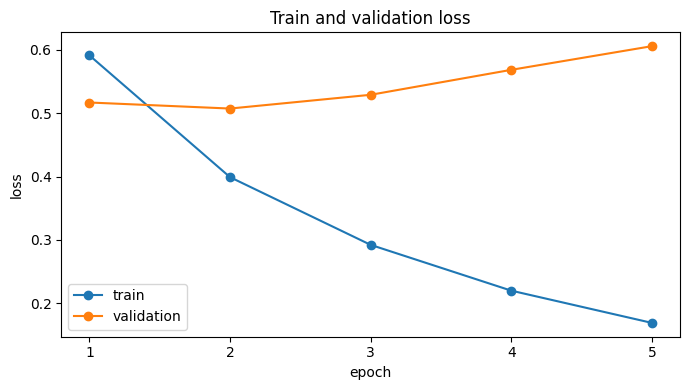

In [20]:
history = []

if RUN_TRAINING:
    best_validation_loss = float("inf")
    for epoch in range(EPOCHS):
        started = time.perf_counter()
        train_loss = train(model, optimizer, train_dataloader)
        validation_loss = evaluation(model, validation_dataloader)
        elapsed_minutes = (time.perf_counter() - started) / 60

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "minutes": elapsed_minutes,
        })
        print(
            f"epoch {epoch + 1}/{EPOCHS} | train {train_loss:.4f} | "
            f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            torch.save(model.state_dict(), MODEL_PATH)
            print("Saved:", MODEL_PATH)

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS / "loss_history.csv", index=False, encoding="utf-8-sig")
    display(history_df)

    plt.figure(figsize=(7, 4))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
    plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Train and validation loss")
    plt.xticks(history_df["epoch"])
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS / "loss_curve.png", dpi=160)
    plt.show()
else:
    print("RUN_TRAINING=False: 학습을 건너뜁니다.")

## 9. 최종 test 평가

이 셀은 모델 설정을 모두 validation으로 결정한 뒤 한 번만 실행합니다. raw baseline의 생성 방식은 greedy decoding(`num_beams=1`)으로 고정합니다.


In [21]:
def generate_predictions(model, dataloader):
    model.eval()
    predictions = []

    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH,
                num_beams=1,
                do_sample=False,
            )
            predictions.extend(
                tokenizer.batch_decode(
                    generated_ids,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
            )
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")

    return [prediction.strip() for prediction in predictions]

if RUN_TRAINING:
    best_model = BartForConditionalGeneration.from_pretrained(
        MODEL_ID,
        revision=model_revision,
        use_safetensors=True,
    ).to(device)
    best_model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))

    test_loss = evaluation(best_model, test_dataloader)
    test_predictions = generate_predictions(best_model, test_dataloader)
    test_references = split_frames["test"]["summary"].astype(str).tolist()

    rouge_metric = evaluate.load("rouge")
    rouge_scores = rouge_metric.compute(
        predictions=test_predictions,
        references=test_references,
        tokenizer=lambda text: text.split(),
        use_stemmer=False,
    )
    test_metrics = {
        "test_loss": test_loss,
        **{name: score * 100 for name, score in rouge_scores.items()},
    }

    prediction_df = split_frames["test"][[
        "row_id", "title", "document", "summary"
    ]].copy()
    prediction_df["prediction"] = test_predictions
    prediction_df.to_csv(
        RESULTS / "test_predictions.csv", index=False, encoding="utf-8-sig"
    )
    (RESULTS / "test_metrics.json").write_text(
        json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    display(pd.Series(test_metrics, name="raw baseline test"))
    display(prediction_df[["title", "summary", "prediction"]].head(10))
else:
    print("RUN_TRAINING=False: test 평가를 건너뜁니다.")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


  generation 200/1,370
  generation 400/1,370
  generation 600/1,370
  generation 800/1,370
  generation 1,000/1,370
  generation 1,200/1,370


test_loss     0.502838
rouge1       35.134365
rouge2       29.319262
rougeL       32.177019
rougeLsum    32.245208
Name: raw baseline test, dtype: float64

,title,summary,prediction
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 ...",아이엘사이언스의 자회사 아이트로닉스는 자동차 주행 중 운전자의 졸음운전을 방지하는 ...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공...,한국형 우주발사체 누리호 의 발사 성공에 힘입어 한국형 우주발사체 누리호 의 발사 ...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만...,30일 이하 현지시간 뉴욕 증시 3대 지수가 모두 하락하며 부진한 상반기 실적으로 ...
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚...,풀무원식품은 깨끗한 자연환경으로 잘 알려진 알래스카에서 자란 고품질의 명태 연육을 ...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부...,일동제약은 생산본부장으로 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학...
5,강릉커피산업 발전·애로기술 해결 의기투합…출연기관 업무협약,5일 기술회사인 커피커퍼가 KIST 강릉천연물연구소와 5일 커피 산업 발전을 위한 ...,한국과학기술연구원 이하 KIST 강릉천연물연구소 한국생산기술연구원 강원본부 한국기초...
6,약세장에 펀드 회전율 5년새 최저…운용기관 방어적 운용 영향,매매에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 140%까지 떨어진...,6펀드평가에 따르면 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하...
7,코오롱 수소 밸류체인 플랫폼 구축… 생산부터 발전까지 원스톱,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022...,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022...
8,에너지정책 유턴 재생에너지 대신 원전으로,정부가 정부가 오늘 국무회의에서 의결한 새 에너지 정책 방향의 주요 내용인 원자력 ...,정부가 새 에너지 정책 방향을 오늘 국무회의에서 의결했는데 지난해 우리나라 발전에서...
9,산업 디지털전환법 오늘부터 시행…“기업 간 협업 프로젝트 지원 확대”,산업디지털전환촉진법 시행을 하루 앞둔 지난 4일 산업부 장영진 제1차관은 산업 디지...,우리 산업 경쟁력을 유지하기 위해선 디지털 전환을 필수라고 보고 이 법 제정을 추진...


## 10. 실험 설정과 산출물 저장

In [22]:
run_config = {
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "test_policy": "original test fixed; overlapping non-test rows excluded",
    "generation": {"num_beams": 1, "do_sample": False},
    "split_counts": {split: len(frame) for split, frame in split_frames.items()},
    "excluded_test_overlap": int(
        manifest["assigned_split"].eq("excluded_test_overlap").sum()
    ),
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

- results\00_baseline_raw_data\best_model_state.pt
- results\00_baseline_raw_data\loss_curve.png
- results\00_baseline_raw_data\loss_history.csv
- results\00_baseline_raw_data\run_config.json
- results\00_baseline_raw_data\split_leakage_check.csv
- results\00_baseline_raw_data\split_manifest.csv
- results\00_baseline_raw_data\split_summary.csv
- results\00_baseline_raw_data\test_metrics.json
- results\00_baseline_raw_data\test_predictions.csv
